# AC2 — Estudo Dirigido 02: Transformações Geométricas

## Objetivo

Desenvolver compreensão de **transformações geométricas 2D** (translação, escala,
rotação, reflexão, cisalhamento e composições) através de implementação prática e
visualização com `numpy` e `matplotlib`.

Cada transformação é implementada como uma **matriz de transformação homogênea 3×3**,
o que permite compor translação com rotação/escala/cisalhamento (que sozinhas são
lineares 2×2, sem translação) numa única multiplicação de matrizes — a mesma técnica
usada em pipelines gráficos (OpenGL, SVG, CSS `transform`).

Um ponto $(x, y)$ é representado em coordenadas homogêneas como $(x, y, 1)$, e cada
transformação $T$ é uma matriz $3\times 3$ tal que $P' = T \cdot P$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)


## Funções base

As seis funções abaixo constroem matrizes de transformação homogênea $3\times 3$.
Todas seguem a mesma convenção: recebem os parâmetros da transformação e devolvem a
matriz — nunca aplicam a transformação diretamente. Isso separa *construir* a
transformação de *aplicá-la*, o que é o que permite compor várias em sequência.


In [2]:
def to_homogeneous(points: np.ndarray) -> np.ndarray:
    """Converte um array de pontos (N, 2) para coordenadas homogêneas (N, 3)."""
    points = np.atleast_2d(points)
    ones = np.ones((points.shape[0], 1))
    return np.hstack([points, ones])


def from_homogeneous(points_h: np.ndarray) -> np.ndarray:
    """Converte de volta para (N, 2), descartando a coordenada homogênea."""
    return points_h[:, :2]


def apply_transform(matrix: np.ndarray, points: np.ndarray) -> np.ndarray:
    """Aplica uma matriz de transformação homogênea 3x3 a pontos (N, 2).

    P' = M · P, com P em coordenadas homogêneas (coluna). Como `points` guarda um
    ponto por linha, a multiplicação é feita como (M @ P_h.T).T.
    """
    points_h = to_homogeneous(points)
    transformed_h = (matrix @ points_h.T).T
    return from_homogeneous(transformed_h)


def translation_matrix(tx: float, ty: float) -> np.ndarray:
    """Matriz de translação por (tx, ty)."""
    return np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1],
    ], dtype=float)


def scale_matrix(sx: float, sy: float) -> np.ndarray:
    """Matriz de escala (uniforme se sx == sy, não uniforme caso contrário)."""
    return np.array([
        [sx, 0, 0],
        [0, sy, 0],
        [0, 0, 1],
    ], dtype=float)


def rotation_matrix(angle_deg: float) -> np.ndarray:
    """Matriz de rotação em torno da origem, ângulo em graus.

    Convenção matemática padrão: ângulo positivo = sentido anti-horário.
    Para rotação horária, passe o ângulo negativo (ex.: -45 para 45° horário).
    """
    theta = np.radians(angle_deg)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    return np.array([
        [cos_t, -sin_t, 0],
        [sin_t,  cos_t, 0],
        [0,      0,     1],
    ], dtype=float)


def reflection_matrix(axis: str) -> np.ndarray:
    """Matriz de reflexão em torno do eixo x ou y.

    Reflexão no eixo x: (x, y) -> (x, -y).
    Reflexão no eixo y: (x, y) -> (-x, y).
    """
    if axis == "x":
        return np.array([[1, 0, 0], [0, -1, 0], [0, 0, 1]], dtype=float)
    if axis == "y":
        return np.array([[-1, 0, 0], [0, 1, 0], [0, 0, 1]], dtype=float)
    raise ValueError('axis deve ser "x" ou "y"')


def shear_matrix(kx: float = 0.0, ky: float = 0.0) -> np.ndarray:
    """Matriz de cisalhamento: kx desloca x proporcionalmente a y, ky o inverso."""
    return np.array([
        [1,  kx, 0],
        [ky, 1,  0],
        [0,  0,  1],
    ], dtype=float)


## Função de visualização

Plota a forma original e a transformada no mesmo eixo, com estilos de linha
diferentes — a mesma estrutura sugerida no enunciado (`plot_shapes`), adaptada para
suportar tanto polígonos (2+ vértices) quanto pontos isolados (1 vértice, plotados
com `scatter`).


In [3]:
def plot_shapes(original: np.ndarray, transformed: np.ndarray, title: str,
                 labels=("Original", "Transformado")):
    """Plota a forma original e a transformada sobrepostas, com eixos e grade."""
    original = np.atleast_2d(original)
    transformed = np.atleast_2d(transformed)

    fig, ax = plt.subplots(figsize=(5.5, 5.5))

    def _draw(pts, label, style):
        if pts.shape[0] == 1:
            ax.scatter(*pts[0], label=label, s=80, zorder=3)
            ax.annotate(f"({pts[0,0]:.2f}, {pts[0,1]:.2f})", pts[0],
                        textcoords="offset points", xytext=(8, 8), fontsize=9)
        else:
            closed = np.vstack([pts, pts[0]])
            ax.plot(closed[:, 0], closed[:, 1], style, label=label)

    _draw(original, labels[0], "-o")
    _draw(transformed, labels[1], "--s")

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend()
    fig.tight_layout()
    plt.show()


---
## Exercício 1 — Translação Simples

Dado o ponto $P(2, 3)$, aplique a translação com vetor $(4, -2)$.

**Perguntas:** Qual é o novo ponto $P'$? Quais coordenadas foram alteradas?


Matriz de translação:
 [[ 1.  0.  4.]
 [ 0.  1. -2.]
 [ 0.  0.  1.]]
P  = [2 3]
P' = [6. 1.]


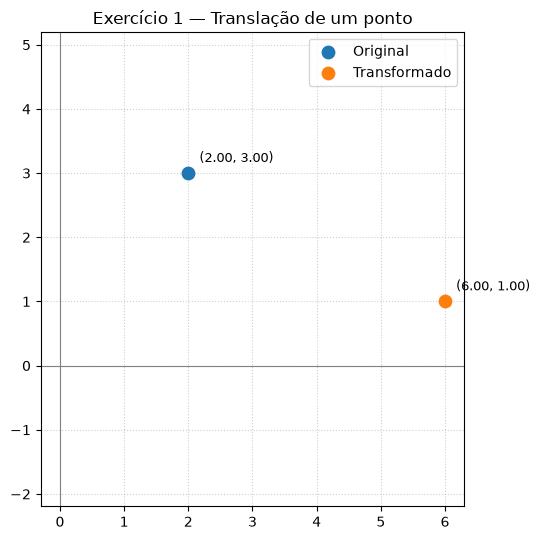

In [4]:
P1 = np.array([[2, 3]])
T1 = translation_matrix(4, -2)
P1_transformed = apply_transform(T1, P1)

print("Matriz de translação:\n", T1)
print(f"P  = {P1[0]}")
print(f"P' = {P1_transformed[0]}")

plot_shapes(P1, P1_transformed, "Exercício 1 — Translação de um ponto")


**Resposta:** $P' = (6, 1)$. Ambas as coordenadas foram alteradas: $x$ passou de
$2$ para $6$ (deslocamento de $+4$) e $y$ passou de $3$ para $1$ (deslocamento de
$-2$), exatamente o vetor de translação aplicado.


---
## Exercício 2 — Escala Uniforme

Considere um triângulo com vértices $A(1,1)$, $B(3,1)$ e $C(2,4)$. Aplique uma
escala uniforme de fator 2.

**Perguntas:** Quais são as novas coordenadas dos vértices após a transformação?
O que acontece com o tamanho do triângulo?


Matriz de escala uniforme:
 [[2. 0. 0.]
 [0. 2. 0.]
 [0. 0. 1.]]
A: [1 1] -> [2. 2.]
B: [3 1] -> [6. 2.]
C: [2 4] -> [4. 8.]


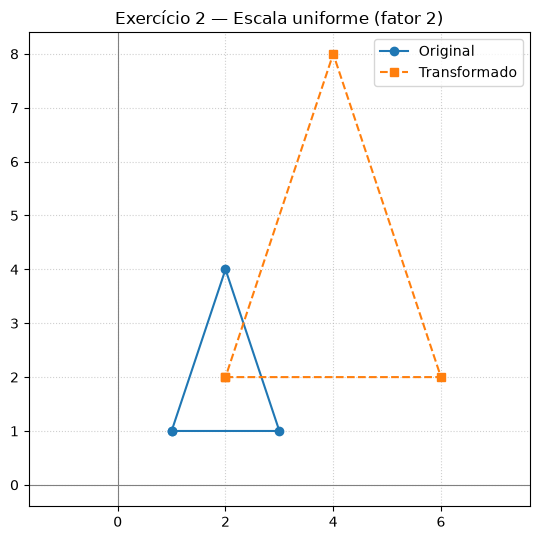

In [5]:
triangle_2 = np.array([[1, 1], [3, 1], [2, 4]])
S2 = scale_matrix(2, 2)
triangle_2_scaled = apply_transform(S2, triangle_2)

print("Matriz de escala uniforme:\n", S2)
for name, before, after in zip("ABC", triangle_2, triangle_2_scaled):
    print(f"{name}: {before} -> {after}")

plot_shapes(triangle_2, triangle_2_scaled, "Exercício 2 — Escala uniforme (fator 2)")


**Resposta:** $A'(2,2)$, $B'(6,2)$, $C'(4,8)$. Como a escala é uniforme (mesmo
fator em $x$ e $y$), o triângulo mantém a mesma forma (os ângulos internos e as
proporções entre os lados não mudam) mas dobra de tamanho: cada lado fica 2× maior
e a área fica $2^2 = 4$× maior.


---
## Exercício 3 — Escala Não Uniforme

Aplique uma escala não uniforme no triângulo do Exercício 2, com fator 2 no eixo
$x$ e fator 0,5 no eixo $y$.

**Pergunta:** Quais são as novas coordenadas dos vértices?


Matriz de escala não uniforme:
 [[2.  0.  0. ]
 [0.  0.5 0. ]
 [0.  0.  1. ]]
A: [1 1] -> [2.  0.5]
B: [3 1] -> [6.  0.5]
C: [2 4] -> [4. 2.]


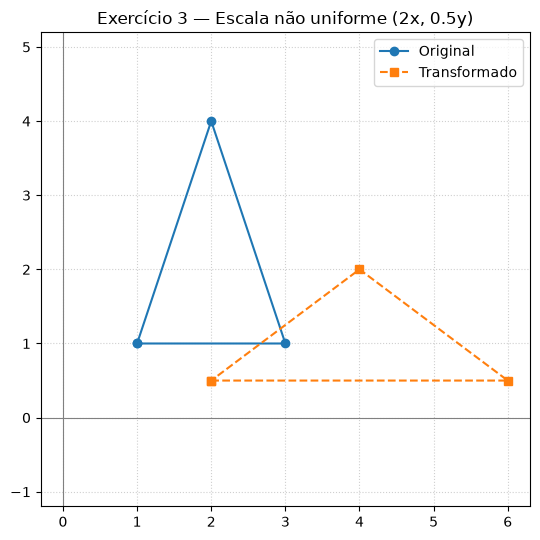

In [6]:
S3 = scale_matrix(2, 0.5)
triangle_3_scaled = apply_transform(S3, triangle_2)

print("Matriz de escala não uniforme:\n", S3)
for name, before, after in zip("ABC", triangle_2, triangle_3_scaled):
    print(f"{name}: {before} -> {after}")

plot_shapes(triangle_2, triangle_3_scaled, "Exercício 3 — Escala não uniforme (2x, 0.5y)")


**Resposta:** $A'(2, 0.5)$, $B'(6, 0.5)$, $C'(4, 2)$. Diferente da escala
uniforme, aqui a forma do triângulo é distorcida: ele fica mais largo (esticado
horizontalmente por 2×) e mais achatado (comprimido verticalmente pela metade),
deixando de ser semelhante ao triângulo original.


---
## Exercício 4 — Rotação em Torno da Origem

Rotacione o ponto $P(1, 0)$ em 90° no sentido anti-horário em torno da origem.

**Pergunta:** Qual é a nova posição do ponto $P'$ após a rotação?


Matriz de rotação (90° anti-horário):
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]
P  = [1 0]
P' = [0. 1.]


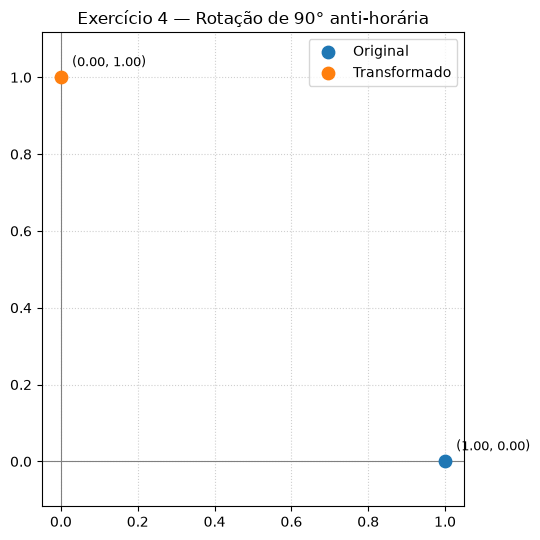

In [7]:
P4 = np.array([[1, 0]])
R4 = rotation_matrix(90)  # positivo = anti-horário
P4_rotated = apply_transform(R4, P4)

print("Matriz de rotação (90° anti-horário):\n", R4)
print(f"P  = {P4[0]}")
print(f"P' = {P4_rotated[0]}")

plot_shapes(P4, P4_rotated, "Exercício 4 — Rotação de 90° anti-horária")


**Resposta:** $P' = (0, 1)$. Uma rotação de 90° anti-horária leva o ponto do eixo
$x$ positivo para o eixo $y$ positivo — o resultado numérico tem um resíduo de
ponto flutuante ($\approx 6 \times 10^{-17}$ na coordenada $x$) devido a
$\cos(90°)$ não ser exatamente zero em aritmética de ponto flutuante, mas o valor
impresso já vem arredondado por `np.set_printoptions`.


---
## Exercício 5 — Rotação de um Polígono

Um quadrado tem vértices $A(1,1)$, $B(1,4)$, $C(4,4)$, $D(4,1)$. Aplique uma
rotação de 45° no sentido horário.

**Pergunta:** Quais são as novas coordenadas dos vértices?


Matriz de rotação (45° horário):
 [[ 0.7071  0.7071  0.    ]
 [-0.7071  0.7071  0.    ]
 [ 0.      0.      1.    ]]
A: [1 1] -> [1.4142 0.    ]
B: [1 4] -> [3.5355 2.1213]
C: [4 4] -> [5.6569 0.    ]
D: [4 1] -> [ 3.5355 -2.1213]


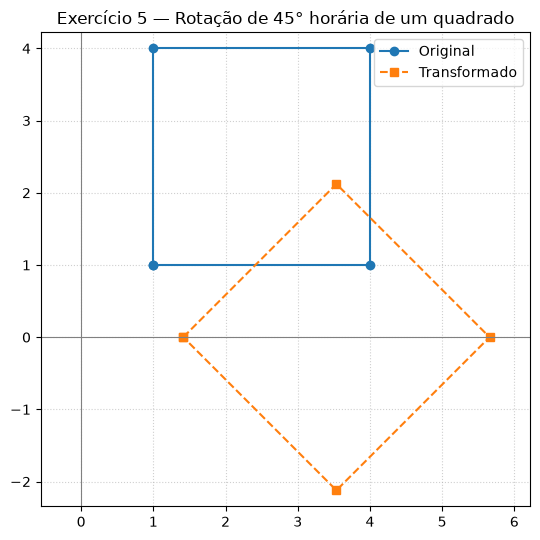

In [8]:
square_5 = np.array([[1, 1], [1, 4], [4, 4], [4, 1]])
R5 = rotation_matrix(-45)  # negativo = sentido horário
square_5_rotated = apply_transform(R5, square_5)

print("Matriz de rotação (45° horário):\n", R5)
for name, before, after in zip("ABCD", square_5, square_5_rotated):
    print(f"{name}: {before} -> {after}")

plot_shapes(square_5, square_5_rotated, "Exercício 5 — Rotação de 45° horária de um quadrado")


**Resposta:** a rotação é em torno da **origem**, não do centro do quadrado —
por isso o quadrado rotacionado aparece deslocado no gráfico, não apenas girado
no lugar. As coordenadas exatas (arredondadas a 4 casas) aparecem no output da
célula acima; note que os lados do quadrado continuam com o mesmo comprimento
(rotação preserva distâncias), apenas orientados a 45° em relação aos eixos.


---
## Exercício 6 — Reflexão Simples

Dado o ponto $P(2, 5)$, aplique uma reflexão em relação ao eixo $y$.

**Pergunta:** Qual é a nova posição do ponto $P'$?


Matriz de reflexão no eixo y:
 [[-1.  0.  0.]
 [ 0.  1.  0.]
 [ 0.  0.  1.]]
P  = [2 5]
P' = [-2.  5.]


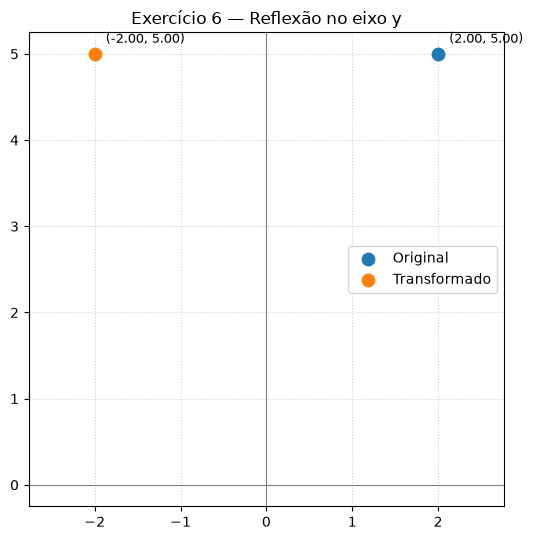

In [9]:
P6 = np.array([[2, 5]])
F6 = reflection_matrix("y")
P6_reflected = apply_transform(F6, P6)

print("Matriz de reflexão no eixo y:\n", F6)
print(f"P  = {P6[0]}")
print(f"P' = {P6_reflected[0]}")

plot_shapes(P6, P6_reflected, "Exercício 6 — Reflexão no eixo y")


**Resposta:** $P' = (-2, 5)$. A reflexão no eixo $y$ inverte o sinal da
coordenada $x$ e preserva $y$ — o ponto "espelha" para o outro lado do eixo
vertical, à mesma altura.


---
## Exercício 7 — Reflexão de um Triângulo

Considere um triângulo com vértices $A(2,3)$, $B(4,3)$ e $C(3,5)$. Aplique uma
reflexão em relação ao eixo $x$.

**Pergunta:** Quais são as novas coordenadas dos vértices após a transformação?


Matriz de reflexão no eixo x:
 [[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  1.]]
A: [2 3] -> [ 2. -3.]
B: [4 3] -> [ 4. -3.]
C: [3 5] -> [ 3. -5.]


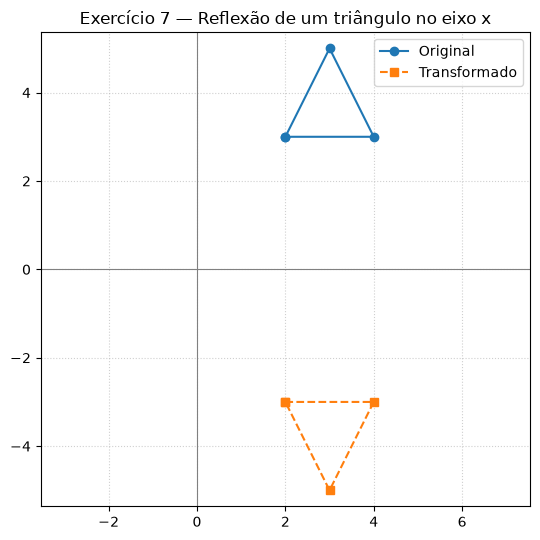

In [10]:
triangle_7 = np.array([[2, 3], [4, 3], [3, 5]])
F7 = reflection_matrix("x")
triangle_7_reflected = apply_transform(F7, triangle_7)

print("Matriz de reflexão no eixo x:\n", F7)
for name, before, after in zip("ABC", triangle_7, triangle_7_reflected):
    print(f"{name}: {before} -> {after}")

plot_shapes(triangle_7, triangle_7_reflected, "Exercício 7 — Reflexão de um triângulo no eixo x")


**Resposta:** $A'(2,-3)$, $B'(4,-3)$, $C'(3,-5)$. A reflexão no eixo $x$
inverte o sinal de todas as coordenadas $y$, mantendo $x$ — o triângulo é
espelhado para baixo do eixo horizontal, e sua orientação (sentido
horário/anti-horário dos vértices) é invertida, embora a forma e o tamanho sejam
preservados.


---
## Exercício 8 — Cisalhamento Horizontal

Dado o ponto $P(2, 3)$, aplique um cisalhamento horizontal com $k = 2$.

**Pergunta:** Qual é a nova posição do ponto $P'$?


Matriz de cisalhamento horizontal (k=2):
 [[1. 2. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
P  = [2 3]
P' = [8. 3.]


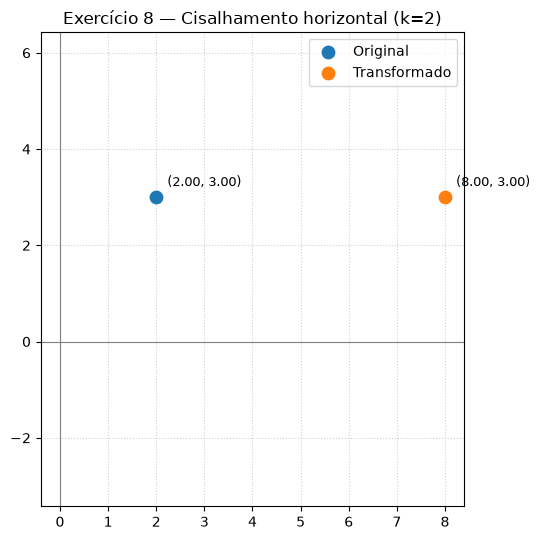

In [11]:
P8 = np.array([[2, 3]])
SH8 = shear_matrix(kx=2)
P8_sheared = apply_transform(SH8, P8)

print("Matriz de cisalhamento horizontal (k=2):\n", SH8)
print(f"P  = {P8[0]}")
print(f"P' = {P8_sheared[0]}")

plot_shapes(P8, P8_sheared, "Exercício 8 — Cisalhamento horizontal (k=2)")


**Resposta:** $P' = (8, 3)$. No cisalhamento horizontal, $x' = x + k \cdot y$ e
$y' = y$ — aqui $x' = 2 + 2 \times 3 = 8$. A coordenada $y$ permanece inalterada;
o deslocamento em $x$ é proporcional ao valor de $y$ (por isso é chamado
*cisalhamento*: pontos com $y$ maior deslocam-se mais).


---
## Exercício 9 — Composição de Transformações

Dado o ponto $P(3, 2)$, aplique as seguintes transformações consecutivas:

1. Translação com vetor $(1, -1)$.
2. Rotação de 90° no sentido anti-horário.
3. Escala uniforme com fator 2.

**Pergunta:** Qual é a nova posição do ponto $P'$ após todas as transformações?

A composição pode ser feita de duas formas equivalentes: aplicando cada matriz em
sequência ao ponto, ou pré-multiplicando as matrizes numa única matriz composta
$M = S \cdot R \cdot T$ (a ordem da multiplicação é da **última** transformação
aplicada para a **primeira**, porque as matrizes atuam da direita para a
esquerda sobre o vetor coluna). As duas formas abaixo produzem o mesmo resultado
— a segunda existe para mostrar como um pipeline gráfico compõe transformações
numa única matriz antes de aplicá-la a todos os pontos de uma cena.


Passo a passo:
  P                    = [3 2]
  após translação      = [4. 1.]
  após rotação 90°     = [-1.  4.]
  após escala x2       = [-2.  8.]

Matriz composta M = S·R·T:
[[ 0. -2.  2.]
 [ 2.  0.  2.]
 [ 0.  0.  1.]]
P' (via matriz composta) = [-2.  8.]


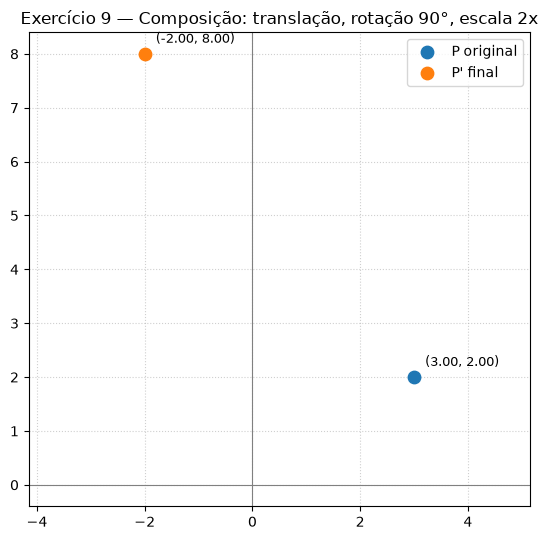

In [12]:
P9 = np.array([[3, 2]])

T9 = translation_matrix(1, -1)
R9 = rotation_matrix(90)
S9 = scale_matrix(2, 2)

# --- Forma 1: aplicar passo a passo ---
step1 = apply_transform(T9, P9)
step2 = apply_transform(R9, step1)
step3 = apply_transform(S9, step2)

print("Passo a passo:")
print(f"  P                    = {P9[0]}")
print(f"  após translação      = {step1[0]}")
print(f"  após rotação 90°     = {step2[0]}")
print(f"  após escala x2       = {step3[0]}")

# --- Forma 2: matriz composta M = S . R . T ---
M9 = S9 @ R9 @ T9
P9_composed = apply_transform(M9, P9)
print(f"\nMatriz composta M = S·R·T:\n{M9}")
print(f"P' (via matriz composta) = {P9_composed[0]}")

plot_shapes(P9, step3, "Exercício 9 — Composição: translação, rotação 90°, escala 2x",
            labels=("P original", "P' final"))


**Resposta:** $P' = (-2, 8)$. Conferindo o passo a passo: $(3,2) \to (4,1)$
(translação) $\to (-1,4)$ (rotação 90° anti-horária) $\to (-2,8)$ (escala 2×). As
duas formas de cálculo (passo a passo e matriz composta) concordam, confirmando
que $M = S \cdot R \cdot T$ é a matriz correta para "primeiro translada, depois
rotaciona, depois escala".


---
## Exercício 10 — Combinação de Transformações em uma Figura

Dado um retângulo com vértices $A(1,1)$, $B(5,1)$, $C(5,3)$, $D(1,3)$, aplique as
seguintes transformações em sequência:

1. Translação com vetor $(-2, 3)$.
2. Escala não uniforme com fatores $1.5$ no eixo $x$ e $0.5$ no eixo $y$.
3. Reflexão em relação ao eixo $y$.

**Pergunta:** Quais são as novas coordenadas dos vértices após as três
transformações?


Matriz composta M = F·S·T:
 [[-1.5  0.   3. ]
 [ 0.   0.5  1.5]
 [ 0.   0.   1. ]]
A: [1 1] -> [1.5 2. ]
B: [5 1] -> [-4.5  2. ]
C: [5 3] -> [-4.5  3. ]
D: [1 3] -> [1.5 3. ]


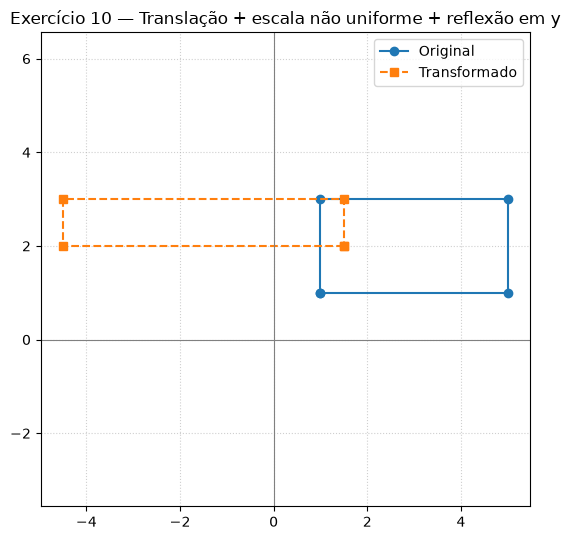

In [13]:
rectangle_10 = np.array([[1, 1], [5, 1], [5, 3], [1, 3]])

T10 = translation_matrix(-2, 3)
S10 = scale_matrix(1.5, 0.5)
F10 = reflection_matrix("y")

# Matriz composta na ordem de aplicação: reflexão(escala(translação(P)))
M10 = F10 @ S10 @ T10
rectangle_10_transformed = apply_transform(M10, rectangle_10)

print("Matriz composta M = F·S·T:\n", M10)
for name, before, after in zip("ABCD", rectangle_10, rectangle_10_transformed):
    print(f"{name}: {before} -> {after}")

plot_shapes(rectangle_10, rectangle_10_transformed,
            "Exercício 10 — Translação + escala não uniforme + reflexão em y")


**Resposta:** as coordenadas finais aparecem no output da célula acima. Passo a
passo: a translação desloca o retângulo para $A(-1,4), B(3,4), C(3,6), D(-1,6)$;
a escala não uniforme estica em $x$ (×1.5) e comprime em $y$ (×0.5), resultando em
$A(-1.5,2), B(4.5,2), C(4.5,3), D(-1.5,3)$; a reflexão em $y$ inverte o sinal de
$x$ em todos os vértices, produzindo o retângulo final espelhado à esquerda da
origem. Note que a ordem das operações importa: aplicar a reflexão antes da
translação, por exemplo, produziria um resultado diferente.


---
## Conclusão

Os dez exercícios cobrem as cinco transformações geométricas 2D fundamentais —
translação, escala (uniforme e não uniforme), rotação, reflexão e
cisalhamento — implementadas de forma **uniforme** como matrizes homogêneas
$3\times 3$. Essa uniformidade é o que torna a composição (Exercícios 9 e 10)
simples: qualquer sequência de transformações vira uma única multiplicação de
matrizes $M = T_n \cdots T_2 \cdot T_1$, aplicada de uma vez a todos os pontos de
uma figura — o mesmo princípio usado em pipelines gráficos reais (matrizes de
model/view/projection em OpenGL/WebGL, `transform-matrix` em SVG e CSS).
